<a href="https://colab.research.google.com/github/witjav/An-lisis-de-riesgo-y-retorno-de-acciones/blob/main/Proyecto_1_An%C3%A1lisis_de_riesgo_y_retorno_de_acciones.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Instalar e importar librerías

- `yfinance`: descarga datos de Yahoo Finance
- `pandas`: manejo de tablas de datos
- `numpy`: cálculos numéricos
- `matplotlib`: gráficos

In [28]:
!pip install yfinance -q

In [29]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")

## 2. Definir parámetros

Cambia estas variables para analizar otras empresas o periodos. Elegí empresas de **sectores distintos** (tecnología, consumo, banca) para que la comparación sea interesante.

In [30]:
tickers = ["AAPL", "MSFT", "KO", "JPM"]   # Apple, Microsoft, Coca-Cola, JPMorgan
inicio = "2019-01-01"
fin = "2025-12-31"
tasa_libre_riesgo = 0.04   # 4% anual, aproximación del rendimiento de bonos del Tesoro de EE. UU.
dias_habiles = 252         # días de bolsa por año

## 3. Descargar los precios

Usamos el precio de cierre **ajustado** (`auto_adjust=True`), que ya incluye dividendos y splits. Es el correcto para calcular retornos.

In [31]:
datos = yf.download(tickers, start=inicio, end=fin, auto_adjust=True)
precios = datos["Close"].dropna()

print(precios.shape)
precios.head()

[*********************100%***********************]  4 of 4 completed

(1759, 4)


Ticker,AAPL,JPM,KO,MSFT
Date,,,,
2019-01-02,37.436924,80.074471,37.120098,94.016136
2019-01-03,33.707924,78.936501,36.890717,90.557495
2019-01-04,35.146889,81.846542,37.626312,94.769249
2019-01-07,35.068653,81.903427,37.135918,94.890129
2019-01-08,35.737183,81.748985,37.555138,95.578133


In [32]:
print(precios.isna().sum())
precios.describe().round(2)

Ticker
AAPL    0
JPM     0
KO      0
MSFT    0
dtype: int64


Ticker,AAPL,JPM,KO,MSFT
count,1759.00,1759.00,1759.00,1759.00
mean,148.00,147.97,51.96,286.56
std,61.03,62.33,9.46,114.89
min,33.71,66.13,30.92,90.56
25%,112.07,103.24,43.96,201.98
50%,149.81,130.85,53.08,272.91
75%,189.00,181.89,57.58,391.05
max,285.41,322.95,71.23,537.65


## 4. Evolución de los precios (base 100)

Los precios de cada empresa están en escalas distintas, así que no se pueden comparar directamente. Los dividimos entre el primer precio y multiplicamos por 100: así todas empiezan en 100 y vemos cuánto creció una inversión inicial.


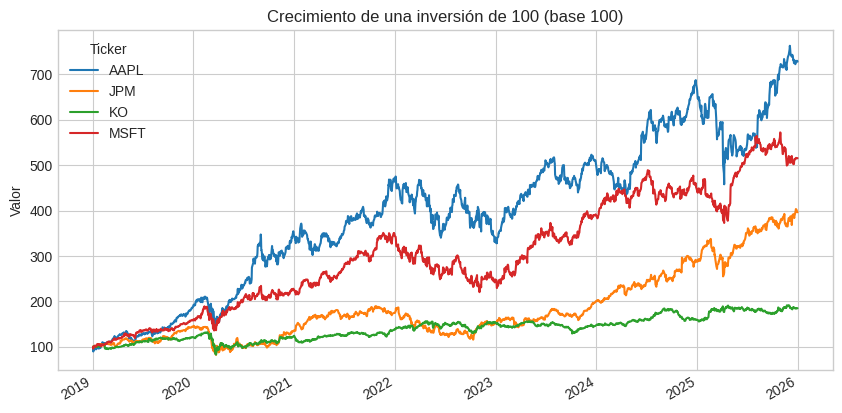

In [33]:
base_100 = precios / precios.iloc[0] * 100

base_100.plot(figsize=(10, 5))
plt.title("Crecimiento de una inversión de 100 (base 100)")
plt.ylabel("Valor")
plt.xlabel("")
plt.show()

## 5. Retornos diarios

El retorno diario es el cambio porcentual del precio de un día al siguiente. Es la base de casi todo el análisis de riesgo.

In [34]:
retornos = precios.pct_change().dropna()
retornos.head()

Ticker,AAPL,JPM,KO,MSFT
Date,,,,
2019-01-03,-0.099608,-0.014211,-0.006179,-0.036788
2019-01-04,0.042689,0.036866,0.019940,0.046509
2019-01-07,-0.002226,0.000695,-0.013033,0.001276
2019-01-08,0.019063,-0.001886,0.011289,0.007251
2019-01-09,0.016981,-0.001691,-0.019166,0.014300


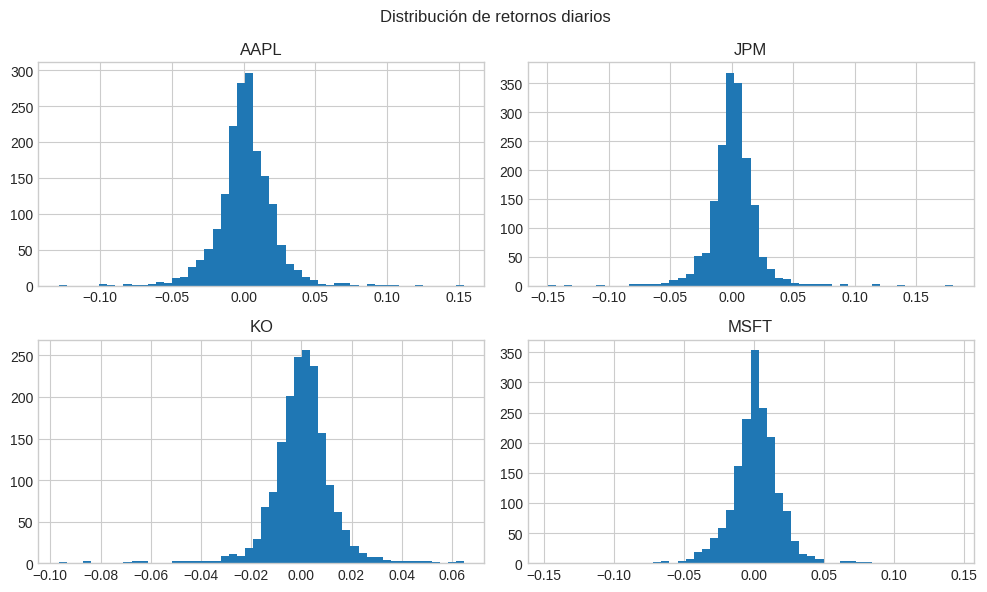

In [35]:
retornos.hist(bins=50, figsize=(10, 6))
plt.suptitle("Distribución de retornos diarios")
plt.tight_layout()
plt.show()

## 6. Métricas clave: retorno, volatilidad y Sharpe

- **Retorno anualizado:** promedio diario × 252
- **Volatilidad anualizada:** desviación estándar diaria × √252 (es la medida de riesgo más usada)
- **Ratio de Sharpe:** (retorno − tasa libre de riesgo) / volatilidad. Indica cuánto retorno extra obtuviste por cada unidad de riesgo. Mientras más alto, mejor.

In [36]:
resumen = pd.DataFrame({
    "Retorno anual": retornos.mean() * dias_habiles,
    "Volatilidad anual": retornos.std() * np.sqrt(dias_habiles),
})
resumen["Sharpe"] = (resumen["Retorno anual"] - tasa_libre_riesgo) / resumen["Volatilidad anual"]

resumen.sort_values("Sharpe", ascending=False).round(3)

,Retorno anual,Volatilidad anual,Sharpe
Ticker,,,
AAPL,0.333,0.311,0.942
MSFT,0.275,0.284,0.829
JPM,0.242,0.299,0.676
KO,0.108,0.199,0.343


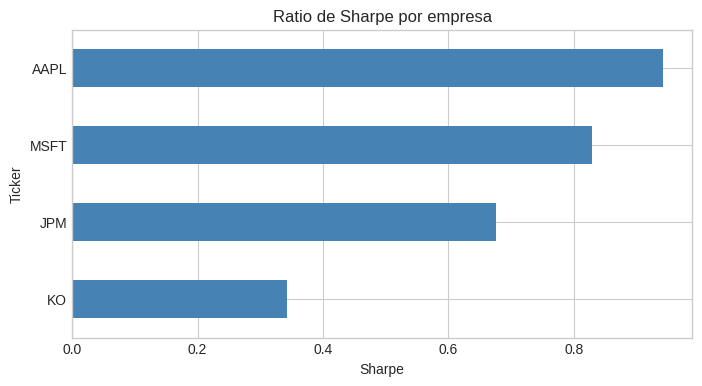

In [37]:
resumen["Sharpe"].sort_values().plot(kind="barh", figsize=(8, 4), color="steelblue")
plt.title("Ratio de Sharpe por empresa")
plt.xlabel("Sharpe")
plt.show()

## 7. Riesgo vs. retorno

Cada punto es una empresa. Lo ideal es estar **arriba** (más retorno) y a la **izquierda** (menos riesgo).


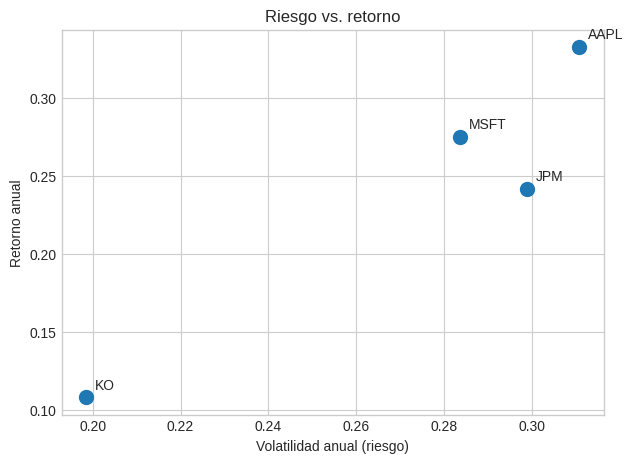

In [38]:
plt.figure(figsize=(7, 5))
plt.scatter(resumen["Volatilidad anual"], resumen["Retorno anual"], s=100)
for t in resumen.index:
    plt.annotate(t, (resumen.loc[t, "Volatilidad anual"], resumen.loc[t, "Retorno anual"]),
                 xytext=(6, 6), textcoords="offset points")
plt.xlabel("Volatilidad anual (riesgo)")
plt.ylabel("Retorno anual")
plt.title("Riesgo vs. retorno")
plt.show()

## 8. Correlaciones

La correlación mide si dos activos se mueven juntos (cercana a 1) o no (cercana a 0). Es la base de la **diversificación**: combinar activos poco correlacionados reduce el riesgo del portafolio.

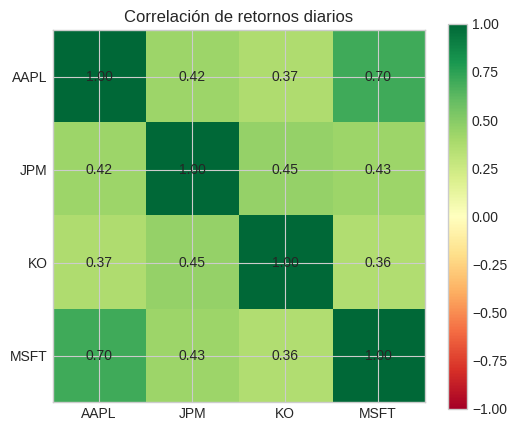

In [39]:
corr = retornos.corr()

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap="RdYlGn", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns)
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")
plt.colorbar(im)
plt.title("Correlación de retornos diarios")
plt.show()

## 9. Caída máxima (*maximum drawdown*)

Es la mayor pérdida desde un máximo hasta el mínimo siguiente. Responde a la pregunta: *"en el peor momento, ¿cuánto habría perdido?"*


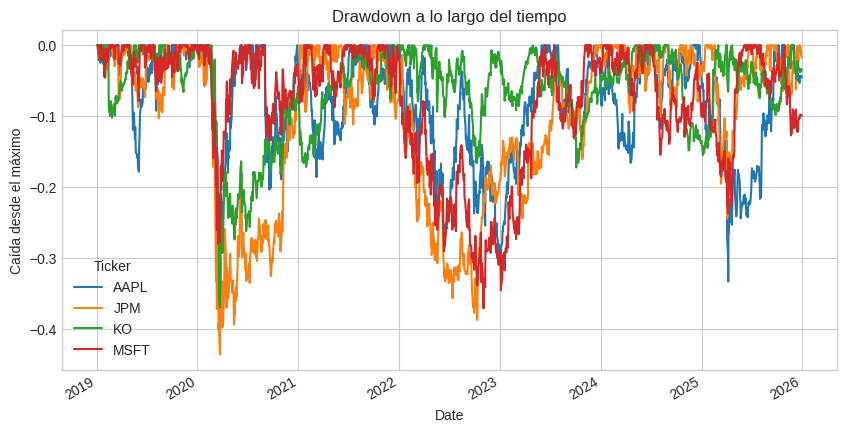

,Retorno anual,Volatilidad anual,Sharpe,Max drawdown
Ticker,,,,
AAPL,0.333,0.311,0.942,-0.334
JPM,0.242,0.299,0.676,-0.436
KO,0.108,0.199,0.343,-0.370
MSFT,0.275,0.284,0.829,-0.371


In [40]:
acumulado = (1 + retornos).cumprod()
maximo_previo = acumulado.cummax()
drawdown = acumulado / maximo_previo - 1

drawdown.plot(figsize=(10, 5))
plt.title("Drawdown a lo largo del tiempo")
plt.ylabel("Caída desde el máximo")
plt.show()

resumen["Max drawdown"] = drawdown.min()
resumen.round(3)

## 10. Conclusiones



## Limitaciones
- Los resultados pasados no garantizan resultados futuros.
- El Sharpe asume que el riesgo es la volatilidad y que los retornos son aproximadamente normales, lo cual no siempre se cumple.
- Solo se analizaron 4 empresas de un mismo mercado; la muestra es pequeña.
- No se consideran costos de transacción ni impuestos.
